# Q1–Q3 floating-island router analysis

This notebook is a reproducible example for `remote-circuit >= 0.10`. It uses only the public experiment/result API: the circuit topology lives in YAML, numerical choices live in TOML, and solver outputs are immutable HDF5 files.

Exact labels are assigned independently at each flux point by dressed-proposer Gale–Shapley matching over the full retained basis. No adjacent-point branch continuation is used.

In [1]:
from importlib.metadata import version
from pathlib import Path

from IPython.display import Image, display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from remote_circuit import (
    load_experiment,
    plot_result,
    read_result,
    run_experiment,
    validate_experiment,
    validate_result,
)

REMOTE_CIRCUIT_VERSION = version("remote-circuit")
major_minor = tuple(int(part) for part in REMOTE_CIRCUIT_VERSION.split(".")[:2])
if major_minor < (0, 10):
    raise RuntimeError(
        f"This notebook requires remote-circuit >= 0.10; the active kernel has "
        f"{REMOTE_CIRCUIT_VERSION}. Relaunch Jupyter with:\n"
        "uv run --with-editable ../remote-circuit --with jupyterlab jupyter lab"
    )

ROOT = Path.cwd().resolve()
if not (ROOT / "pyproject.toml").is_file():
    ROOT = next(parent for parent in ROOT.parents if (parent / "pyproject.toml").is_file())

EXPERIMENTS = ROOT / "experiments"
RESULTS = ROOT / "results"
SMOKE_CONFIG = EXPERIMENTS / "q1-q3-smoke.toml"
BASELINE_CONFIG = EXPERIMENTS / "q1-q3-baseline.toml"
BASELINE_PATH = RESULTS / "q1-q3-baseline-v2.h5"
CONVERGENCE_PATHS = sorted(RESULTS.glob("q1-q3-convergence-*-v2.h5"))

plt.rcParams.update({"figure.figsize": (9, 5), "axes.grid": True})
print("remote-circuit", REMOTE_CIRCUIT_VERSION)

remote-circuit 0.10.0


## 1. Preflight the declarative inputs

`validate_experiment` performs topology, subsystem, control, method, unit, and numerical-option checks without starting a sweep.

In [2]:
smoke_spec = load_experiment(SMOKE_CONFIG)
baseline_spec = load_experiment(BASELINE_CONFIG)
validate_experiment(smoke_spec)
validate_experiment(baseline_spec)

print({
    "model": baseline_spec.model_type,
    "schema": baseline_spec.schema_version,
    "circuit": baseline_spec.circuit.topology.name,
    "qubits": baseline_spec.circuit.topology.parameters["computational_qubits"],
    "methods": baseline_spec.methods.enabled,
    "preset": baseline_spec.numerics.preset,
})

{'model': 'floating_island_router', 'schema': 2, 'circuit': 'floating-island-q1-q3', 'qubits': ['Q1', 'Q3'], 'methods': ('exact', 'schrieffer_wolff'), 'preset': 'converged'}


## 2. Run the two-point smoke experiment

The smoke result is computed once and then reused. Delete the HDF5 file explicitly if you intend to recompute it; result files are immutable by design.

In [3]:
smoke_path = smoke_spec.output.directory / smoke_spec.output.basename
if smoke_path.is_file():
    smoke = read_result(smoke_path)
else:
    smoke = run_experiment(smoke_spec)
    smoke.save(smoke_path)

smoke_report = validate_result(smoke)
assert smoke_report["ok"], smoke_report["errors"]
print(smoke_path)
print("warnings:", smoke_report["warnings"])
print({key: smoke.metadata[key] for key in (
    "assignment_algorithm", "assignment_scope", "assignment_proposer",
    "circuit_fingerprint", "git_commit", "git_dirty",
)})

/Users/yalgaeahn/Research/20_Projects/floating-router-study/results/q1-q3-smoke-v2.h5
warnings: []
{'assignment_algorithm': 'gale-shapley', 'assignment_scope': 'full retained basis', 'assignment_proposer': 'dressed', 'circuit_fingerprint': '152cdff49d99b2295741849e0e609d5be11815aed5e621530bb7575d89d76a0c', 'git_commit': '19d0a4a69f9a32da5903d98b957f8972e984deef', 'git_dirty': np.True_}


## 3. Load the publication-scale baseline

The 101-point baseline is intentionally not launched from the notebook. Run it from a terminal so the long calculation remains visible and restartable:

```bash
uv run --with-editable ../remote-circuit python scripts/run_q1_q3.py baseline
```

In [4]:
baseline = read_result(BASELINE_PATH) if BASELINE_PATH.is_file() else None
convergence = {path.stem: read_result(path) for path in CONVERGENCE_PATHS}

if baseline is None:
    print("Missing baseline:", BASELINE_PATH)
else:
    expected = {
        "assignment_algorithm": "gale-shapley",
        "exact_reference_assignment": "pointwise dressed-proposer Gale-Shapley",
        "assignment_scope": "full retained basis",
        "assignment_proposer": "dressed",
    }
    for key, value in expected.items():
        assert baseline.metadata[key] == value, (key, baseline.metadata[key])
    print({key: baseline.metadata[key] for key in expected})

print(f"convergence results: {len(convergence)}/8")

{'assignment_algorithm': 'gale-shapley', 'exact_reference_assignment': 'pointwise dressed-proposer Gale-Shapley', 'assignment_scope': 'full retained basis', 'assignment_proposer': 'dressed'}
convergence results: 0/8


## 4. Dressed manifolds, interactions, and assignment diagnostics

The public `plot_result` API dispatches to the floating-island visualizer and writes reproducible PNG/PDF artifacts. PNG files are displayed inline below. Curves are reconstructed from the stored full eigenspectrum and pointwise assignment; index changes break a curve rather than implying continuity between neighboring flux points.

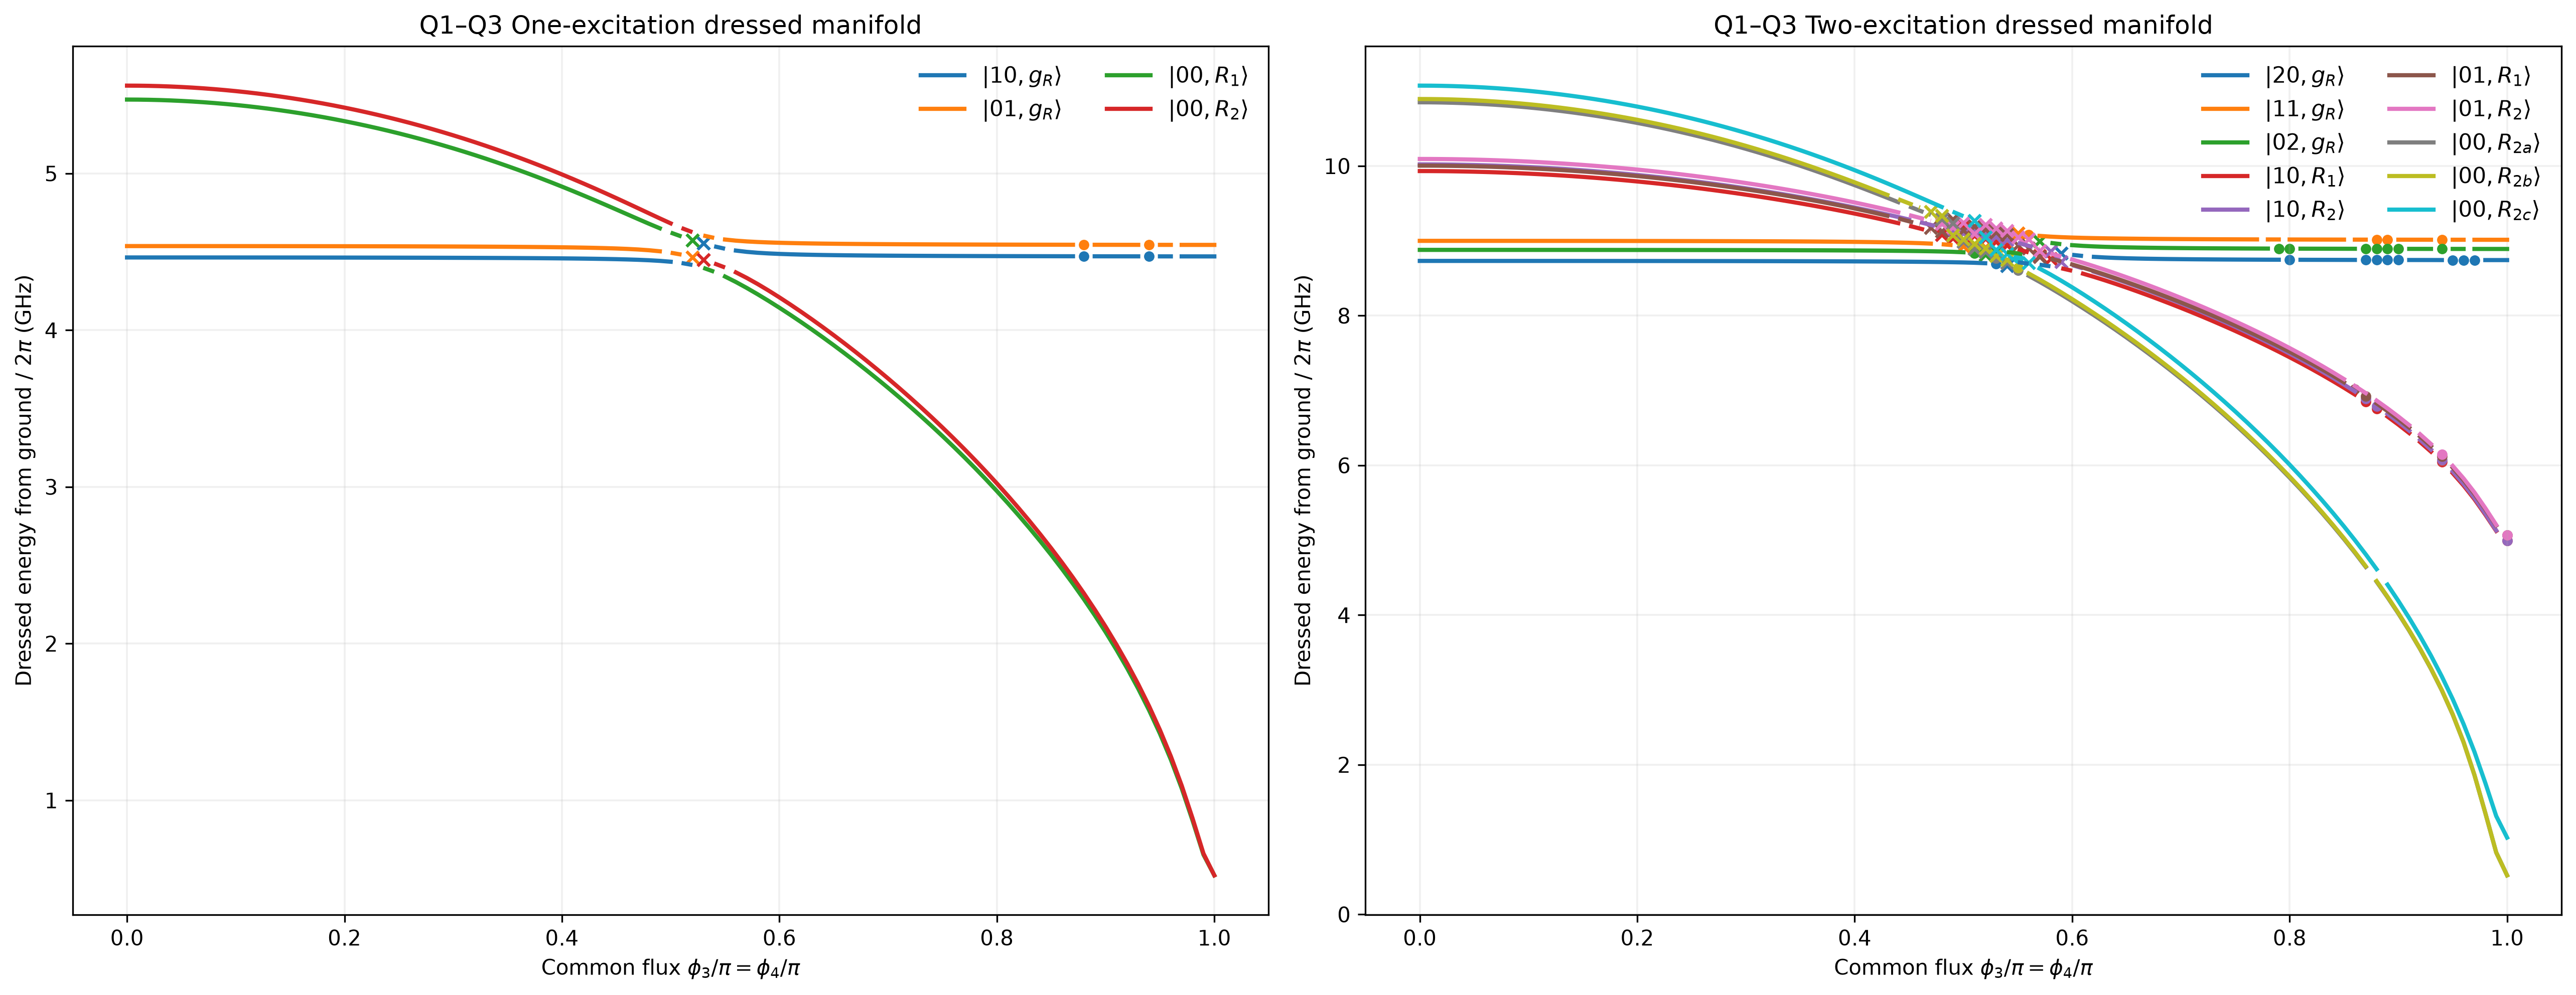

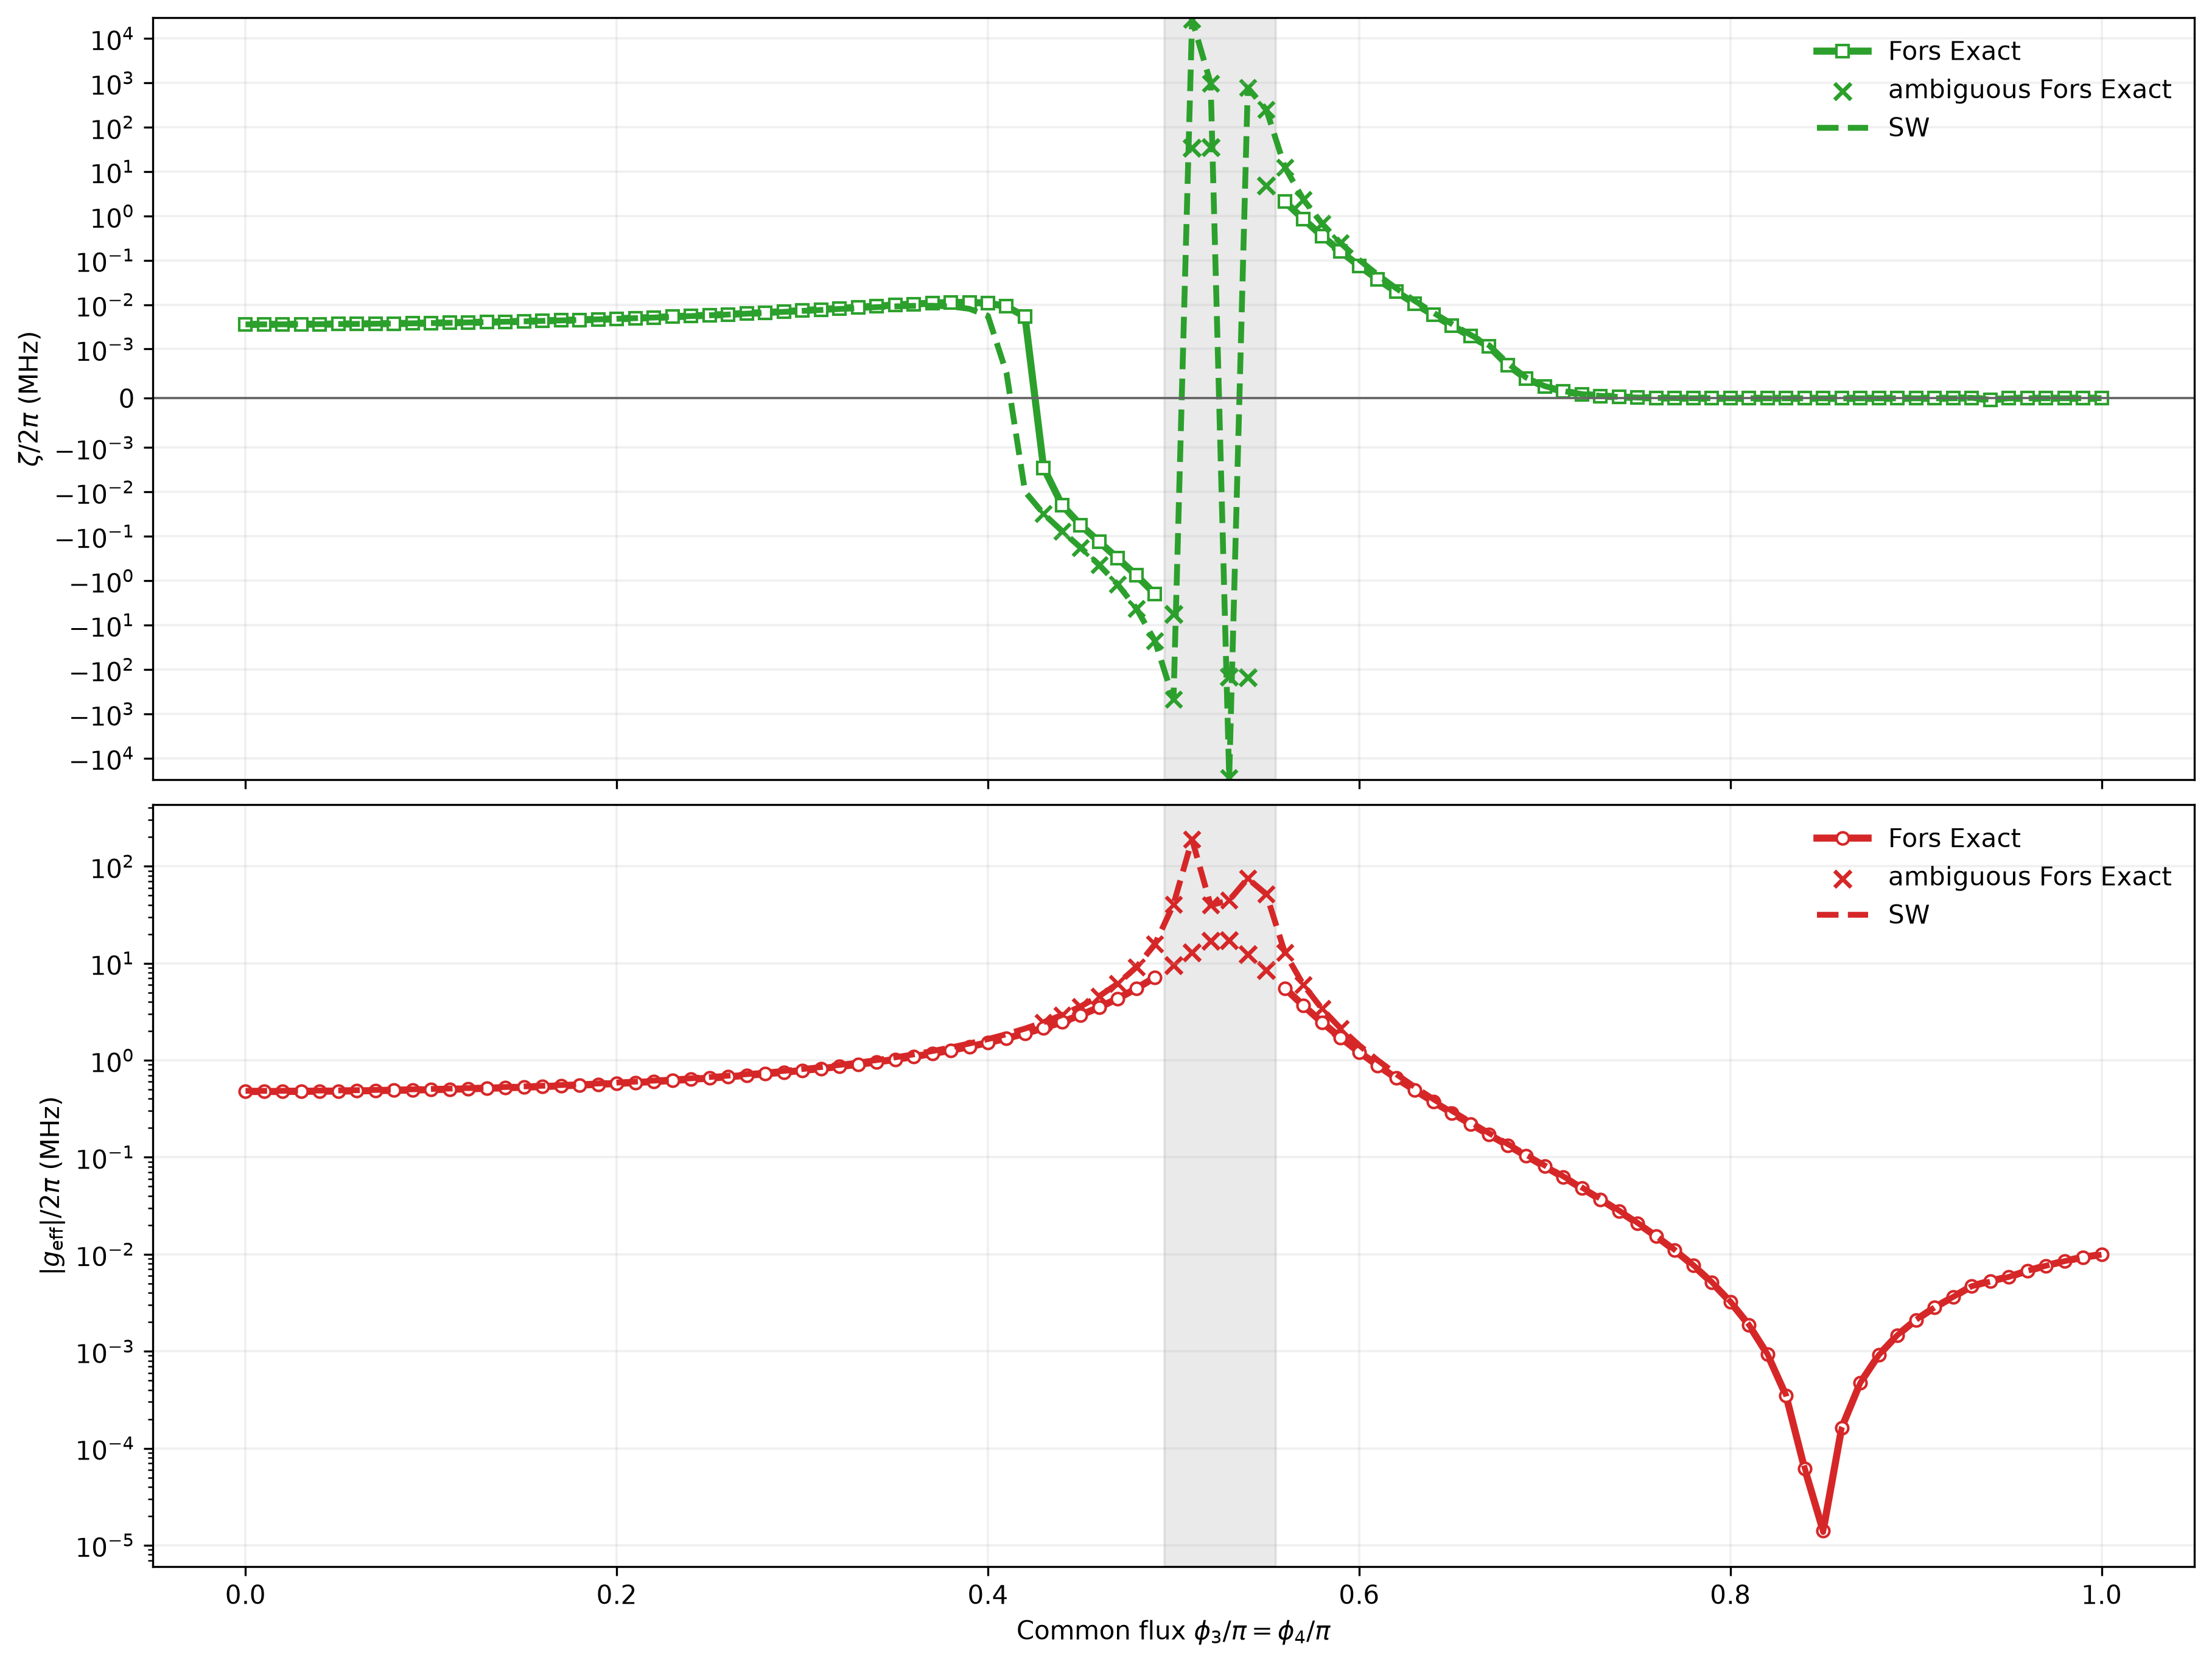

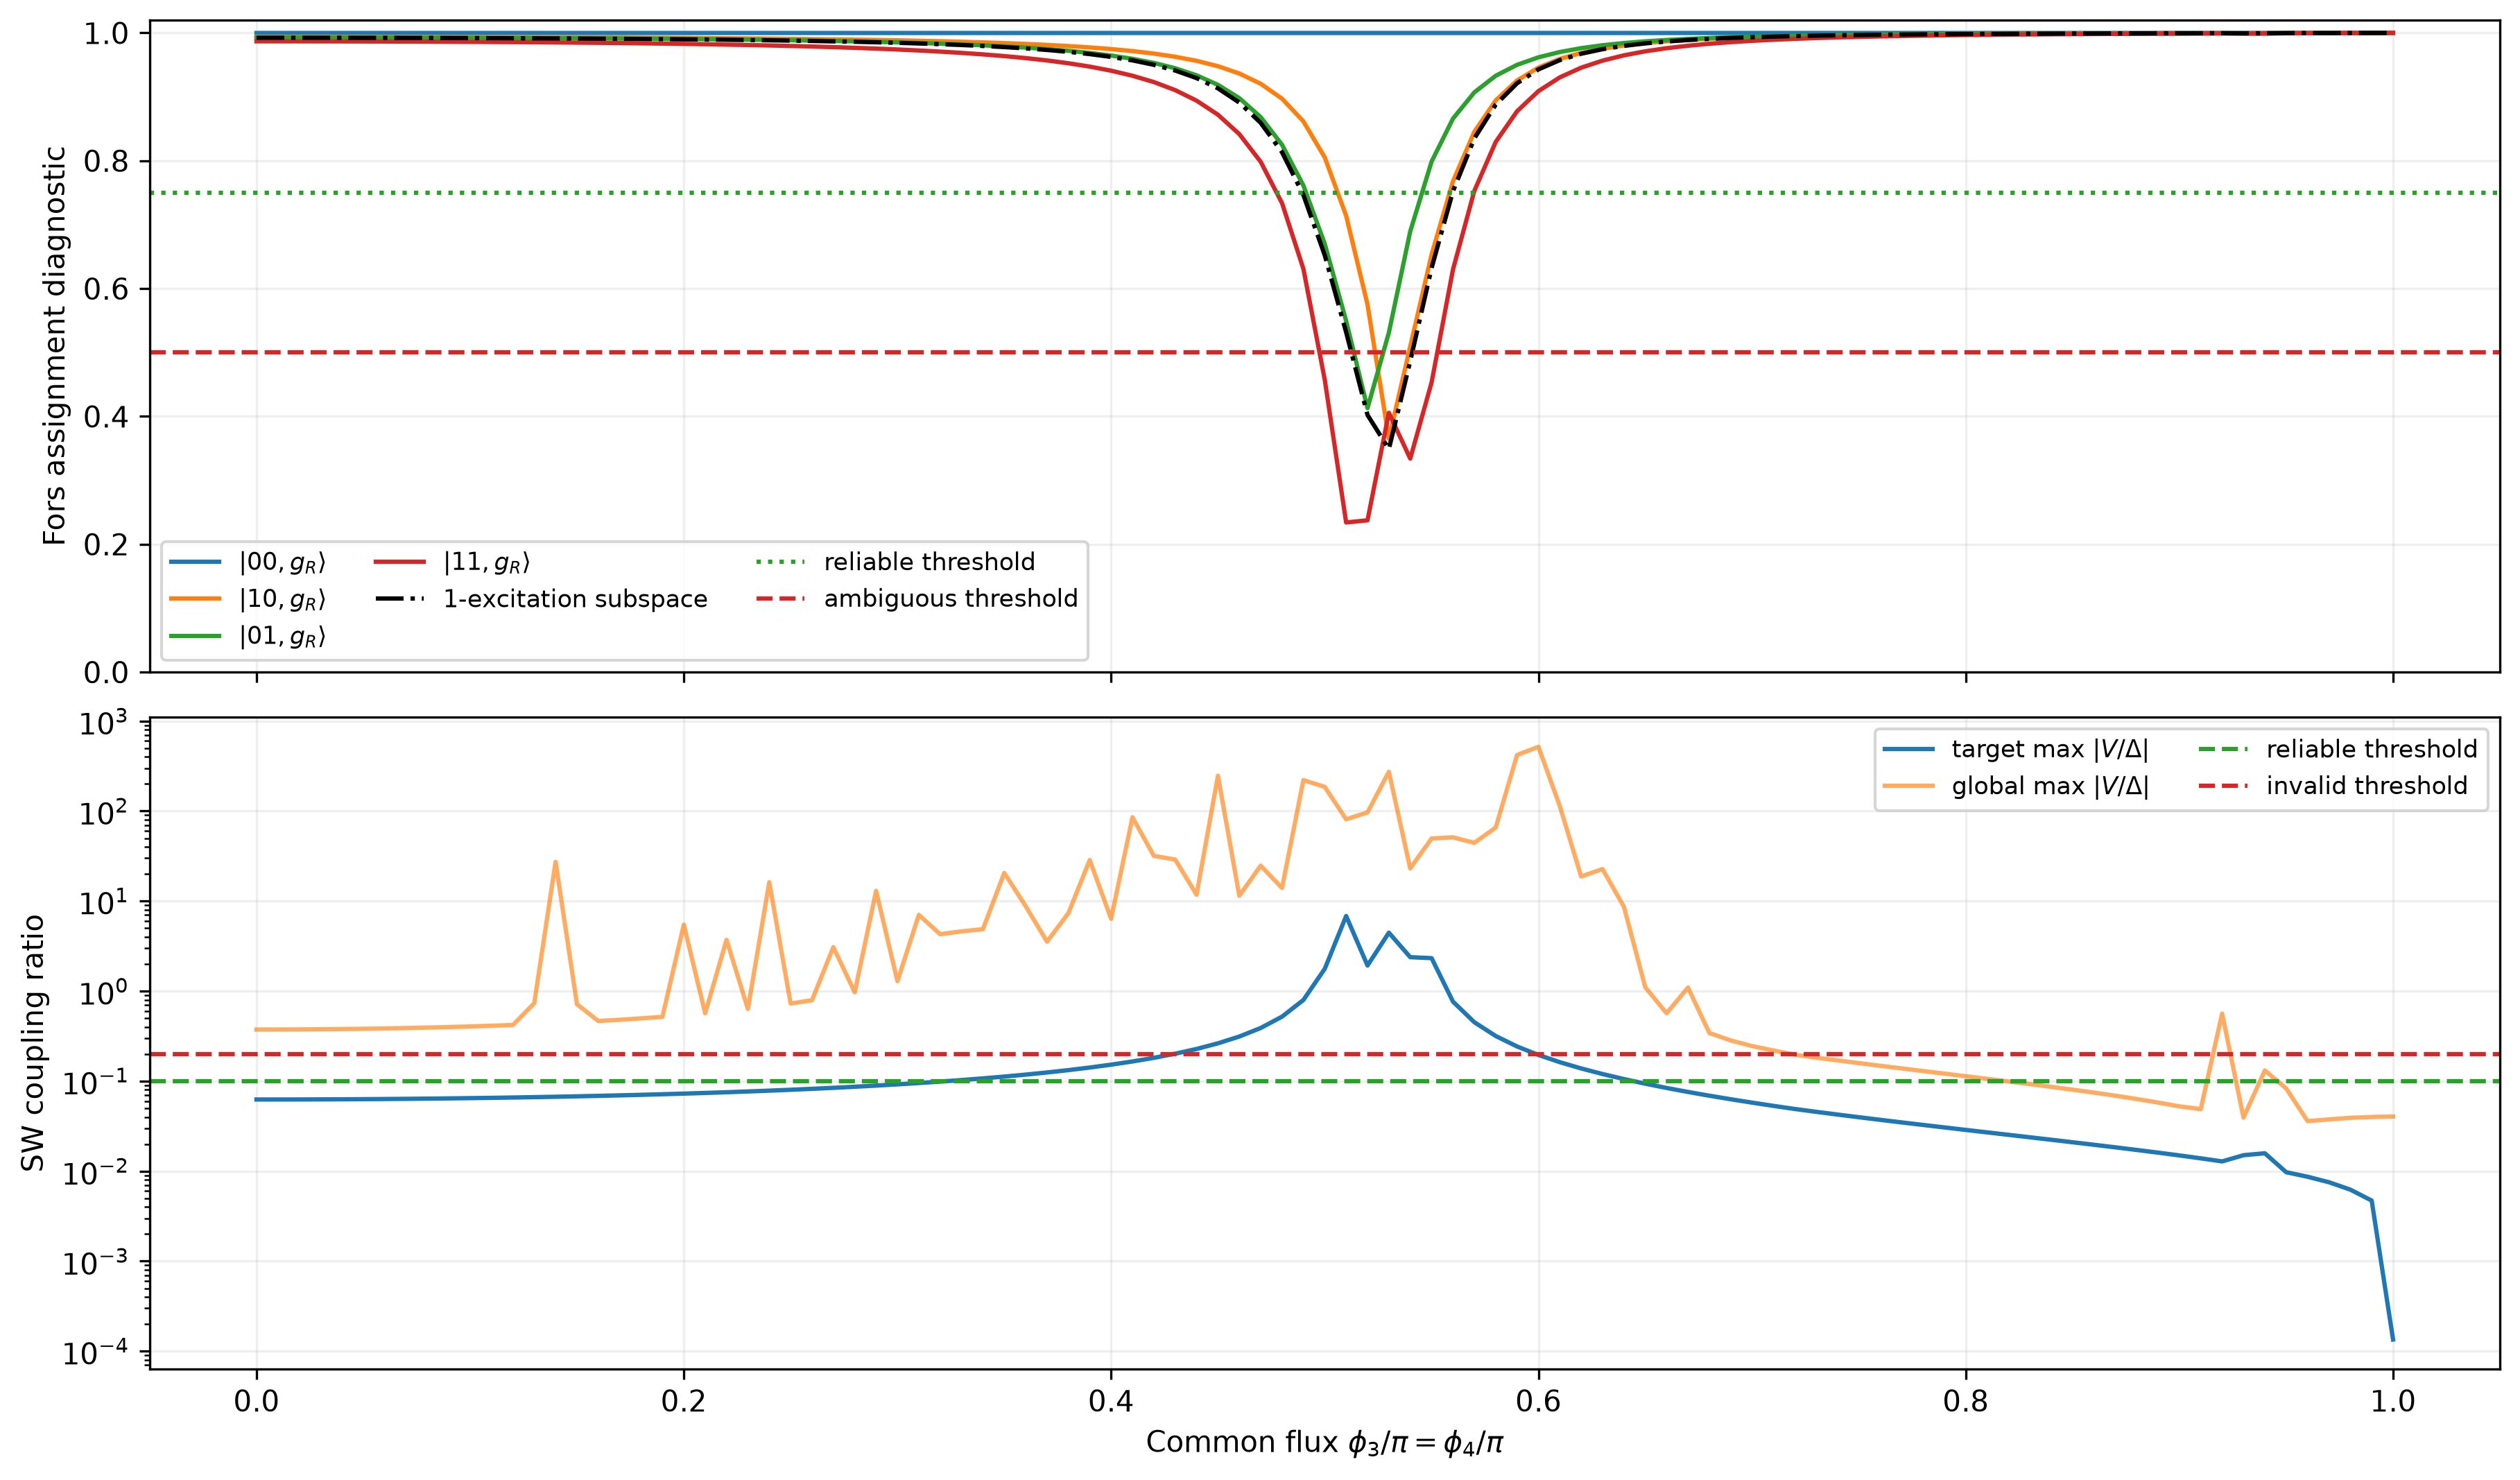

In [5]:
if baseline is not None:
    plot_directory = RESULTS / "q1-q3-baseline-v2-plots"
    plot_paths = plot_result(baseline, plot_directory)
    for plot_path in plot_paths:
        if plot_path.suffix.lower() == ".png":
            display(Image(filename=str(plot_path)))
else:
    print("Baseline plots will appear after the terminal baseline run.")

## 5. Compact numerical summary

Ambiguous Exact samples remain in the table and plots. The validity/status columns determine how they should be interpreted; they are not silently dropped.

In [6]:
if baseline is not None:
    frame = baseline.observables["common"]
    flux = np.asarray(baseline.coordinates["common"])
    summary_frame = pd.DataFrame({
        "phi_over_pi": flux,
        "exact_zz_khz": np.asarray(frame["exact_zz_khz"]),
        "sw5_zz_khz": np.asarray(frame["sw_zz_order_5_khz"]),
        "exact_abs_j_mhz": np.asarray(frame["exact_abs_j_mhz"]),
        "minimum_overlap": np.asarray(frame["exact_minimum_overlap"]),
        "exact_status": np.asarray(frame["exact_status"]).astype(str),
        "sw_status": np.asarray(frame["sw_status"]).astype(str),
    })
    display(summary_frame.head())
    display(summary_frame[["exact_status", "sw_status"]].value_counts())
else:
    summary_frame = pd.DataFrame()
    print("No baseline summary yet.")

,phi_over_pi,exact_zz_khz,sw5_zz_khz,exact_abs_j_mhz,minimum_overlap,exact_status,sw_status
0,0.00,3.589303,3.594202,0.476162,0.986819,reliable,reliable
1,0.01,3.591745,3.596636,0.476367,0.986811,reliable,reliable
2,0.02,3.599086,3.603952,0.476983,0.986787,reliable,reliable
3,0.03,3.611373,3.616197,0.478014,0.986746,reliable,reliable
4,0.04,3.628685,3.633447,0.479465,0.986689,reliable,reliable


exact_status  sw_status 
reliable      reliable      69
              borderline    15
              invalid        8
ambiguous     invalid        6
borderline    invalid        3
Name: count, dtype: int64

## 6. Charge-cutoff and retained-dimension convergence

Each curve is compared with the largest setting in its family. Both the router spectrum and interaction observables should stabilize before a baseline is used for a paper figure.

In [7]:
records = []
for name, result in convergence.items():
    router_options = result.config["numerics"]["components"]["R"]
    kind = "ncut" if "ncut-" in name else "dim"
    value = int(router_options["ncut"] if kind == "ncut" else router_options["truncated_dim"])
    frame = result.observables["common"]
    records.append({
        "kind": kind,
        "value": value,
        "router": np.asarray(frame["router_transition_1_ghz"]),
        "zz": np.asarray(frame["exact_zz_khz"]),
        "sw5": np.asarray(frame["sw_zz_order_5_khz"]),
    })

summary_rows = []
for kind in ("ncut", "dim"):
    group = sorted((row for row in records if row["kind"] == kind), key=lambda row: row["value"])
    if group:
        reference = group[-1]
        for row in group:
            summary_rows.append({
                "kind": kind,
                "value": row["value"],
                "max_router_error_khz": 1e6 * np.max(np.abs(row["router"] - reference["router"])),
                "max_exact_zz_error_khz": np.max(np.abs(row["zz"] - reference["zz"])),
                "max_sw5_zz_error_khz": np.max(np.abs(row["sw5"] - reference["sw5"])),
            })

convergence_summary = pd.DataFrame(summary_rows)
convergence_summary

""


In [8]:
if not convergence_summary.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
    for axis, kind in zip(axes, ("ncut", "dim"), strict=True):
        subset = convergence_summary[convergence_summary["kind"] == kind]
        for key, label in (
            ("max_router_error_khz", "router"),
            ("max_exact_zz_error_khz", "Exact ZZ"),
            ("max_sw5_zz_error_khz", "SW5 ZZ"),
        ):
            axis.semilogy(subset["value"], np.maximum(subset[key], 1e-12), "o-", label=label)
        axis.set(xlabel=kind, ylabel="max difference from largest setting (kHz)")
        axis.legend()
    plt.show()
else:
    print("Run: uv run --with-editable ../remote-circuit python scripts/run_q1_q3.py convergence")

Run: uv run --with-editable ../remote-circuit python scripts/run_q1_q3.py convergence


## Interpretation checklist

- Use Exact as a reference only where pointwise GS diagnostics support the assignment.
- Preserve borderline and ambiguous points instead of dropping them.
- Confirm both router-spectrum and `ZZ`/exchange convergence before using the 101-point result.
- Keep the experiment TOML, circuit YAML, package revision, and summary CSV with any paper artifact.
- Increase truncation settings through explicit `numerics.components` overrides; do not modify library source files.